<a href="https://colab.research.google.com/github/jatinkumar-creator/machine-learning-portfolio/blob/main/06_Ensemble_Learning/notebooks/03_Ensemble_Learning_End_to_End_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Wine Classification Using Ensemble Learning

## Project Overview
This project implements and compares multiple machine learning
and ensemble learning algorithms to classify wine categories.

## Objectives
- Understand the Wine dataset.
- Perform exploratory data analysis.
- Split data into training and testing sets.
- Train multiple machine learning models.
- Apply cross-validation.
- Perform hyperparameter tuning.
- Compare model performance.
- Evaluate the final model.

## Algorithms
- Decision Tree
- Random Forest
- AdaBoost
- Gradient Boosting
- Voting Classifier
- Stacking Classifier

## Evaluation Metrics
- Accuracy
- Precision
- Recall
- F1-score
- Confusion Matrix

In [1]:
#Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine

from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    GridSearchCV
)

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier,
    VotingClassifier,
    StackingClassifier
)

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [2]:
#Load the dataset
wine = load_wine()

X = pd.DataFrame(
    wine.data,
    columns=wine.feature_names
)

y = pd.Series(wine.target, name="wine_class")

print("Dataset loaded successfully")

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nClass names:")
print(wine.target_names)

Dataset loaded successfully
Features shape: (178, 13)
Target shape: (178,)

Class names:
['class_0' 'class_1' 'class_2']


In [3]:
#Exploratory Data Analysis (EDA)
#Inspect the dataset
print("First five records:")
display(X.head())

print("\nDataset information:")
print(X.info())

print("\nStatistical summary:")
display(X.describe())

print("\nMissing values:")
print(X.isnull().sum())

print("\nDuplicate records:")
print(X.duplicated().sum())

First five records:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 13 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proline                       178 non-null

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000
mean,13.000618,2.336348,2.366517,19.494944,99.741573,2.295112,2.029270,0.361854,1.590899,5.058090,0.957449,2.611685,746.893258
std,0.811827,1.117146,0.274344,3.339564,14.282484,0.625851,0.998859,0.124453,0.572359,2.318286,0.228572,0.709990,314.907474
min,11.030000,0.740000,1.360000,10.600000,70.000000,0.980000,0.340000,0.130000,0.410000,1.280000,0.480000,1.270000,278.000000
25%,12.362500,1.602500,2.210000,17.200000,88.000000,1.742500,1.205000,0.270000,1.250000,3.220000,0.782500,1.937500,500.500000
50%,13.050000,1.865000,2.360000,19.500000,98.000000,2.355000,2.135000,0.340000,1.555000,4.690000,0.965000,2.780000,673.500000
75%,13.677500,3.082500,2.557500,21.500000,107.000000,2.800000,2.875000,0.437500,1.950000,6.200000,1.120000,3.170000,985.000000
max,14.830000,5.800000,3.230000,30.000000,162.000000,3.880000,5.080000,0.660000,3.580000,13.000000,1.710000,4.000000,1680.000000



Missing values:
alcohol                         0
malic_acid                      0
ash                             0
alcalinity_of_ash               0
magnesium                       0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 0
color_intensity                 0
hue                             0
od280/od315_of_diluted_wines    0
proline                         0
dtype: int64

Duplicate records:
0


wine_class
0    59
1    71
2    48
Name: count, dtype: int64


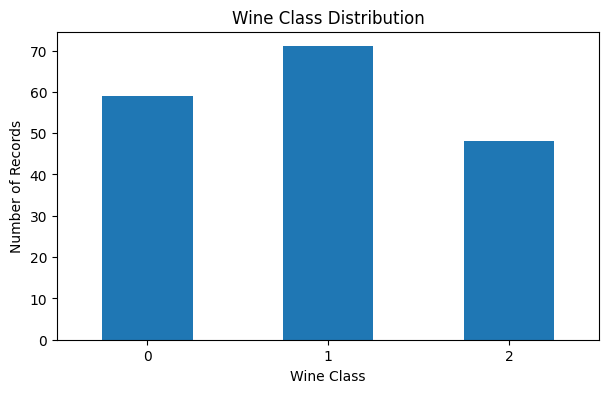

In [4]:
#Class distribution
print(y.value_counts().sort_index())

plt.figure(figsize=(7, 4))

y.value_counts().sort_index().plot(kind="bar")

plt.title("Wine Class Distribution")
plt.xlabel("Wine Class")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)

plt.show()

In [5]:
#Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 142
Testing samples: 36


In [6]:
#Build multiple models
#Create individual models
dt_model = DecisionTreeClassifier(
    random_state=42
)

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

ada_model = AdaBoostClassifier(
    n_estimators=50,
    random_state=42
)

gb_model = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    random_state=42
)

In [7]:
#Create Voting and Stacking models
logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=2000))
])

knn_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", KNeighborsClassifier(n_neighbors=5))
])

In [8]:
#Voting Classifier
voting_model = VotingClassifier(
    estimators=[
        ("lr", logistic_model),
        ("dt", dt_model),
        ("knn", knn_model)
    ],
    voting="soft"
)

In [9]:
#Stacking Classifier
stacking_model = StackingClassifier(
    estimators=[
        ("lr", logistic_model),
        ("dt", dt_model),
        ("knn", knn_model)
    ],
    final_estimator=LogisticRegression(max_iter=2000),
    cv=5
)

In [10]:
#Train all models
models = {
    "Decision Tree": dt_model,
    "Random Forest": rf_model,
    "AdaBoost": ada_model,
    "Gradient Boosting": gb_model,
    "Voting Classifier": voting_model,
    "Stacking Classifier": stacking_model
}

for name, model in models.items():

    model.fit(X_train, y_train)

    print(name, "trained successfully")

Decision Tree trained successfully
Random Forest trained successfully
AdaBoost trained successfully
Gradient Boosting trained successfully
Voting Classifier trained successfully
Stacking Classifier trained successfully


In [11]:
#Cross-validation
cv_results = []

for name, model in models.items():

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=5,
        scoring="accuracy"
    )

    cv_results.append({
        "Model": name,
        "Mean CV Accuracy": scores.mean(),
        "Standard Deviation": scores.std()
    })

cv_results = pd.DataFrame(cv_results)

display(
    cv_results.sort_values(
        by="Mean CV Accuracy",
        ascending=False
    )
)

,Model,Mean CV Accuracy,Standard Deviation
5,Stacking Classifier,0.993103,0.013793
1,Random Forest,0.986207,0.027586
4,Voting Classifier,0.986207,0.016893
2,AdaBoost,0.964778,0.039128
3,Gradient Boosting,0.958374,0.040174
0,Decision Tree,0.916256,0.051359


In [12]:
#Hyperparameter tuning
param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [None, 3, 5, 10],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2]
}

grid_search = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best parameters:")
print(grid_search.best_params_)

print("\nBest cross-validation accuracy:")
print(grid_search.best_score_)

Best parameters:
{'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 100}

Best cross-validation accuracy:
0.9862068965517242


In [13]:
#Get the optimized model
best_rf_model = grid_search.best_estimator_

print("Optimized Random Forest ready.")

Optimized Random Forest ready.


In [14]:
#Final model evaluation
final_models = {
    "Decision Tree": dt_model,
    "Random Forest": rf_model,
    "AdaBoost": ada_model,
    "Gradient Boosting": gb_model,
    "Voting Classifier": voting_model,
    "Stacking Classifier": stacking_model,
    "Optimized Random Forest": best_rf_model
}

test_results = []

for name, model in final_models.items():

    predictions = model.predict(X_test)

    test_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, average="weighted", zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, average="weighted", zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, predictions, average="weighted", zero_division=0
        )
    })

test_results = pd.DataFrame(test_results)

display(
    test_results.sort_values(
        by="F1 Score",
        ascending=False
    )
)

,Model,Accuracy,Precision,Recall,F1 Score
1,Random Forest,1.000000,1.000000,1.000000,1.000000
6,Optimized Random Forest,1.000000,1.000000,1.000000,1.000000
5,Stacking Classifier,0.972222,0.974074,0.972222,0.971970
4,Voting Classifier,0.944444,0.951389,0.944444,0.944961
0,Decision Tree,0.944444,0.951389,0.944444,0.944961
3,Gradient Boosting,0.944444,0.946581,0.944444,0.944269
2,AdaBoost,0.916667,0.922466,0.916667,0.916529


In [22]:
cv_results.sort_values(
    by="Mean CV Accuracy",
    ascending=False
)

,Model,Mean CV Accuracy,Standard Deviation
5,Stacking Classifier,0.993103,0.013793
1,Random Forest,0.986207,0.027586
4,Voting Classifier,0.986207,0.016893
2,AdaBoost,0.964778,0.039128
3,Gradient Boosting,0.958374,0.040174
0,Decision Tree,0.916256,0.051359


In [23]:
from sklearn.model_selection import cross_val_score

# Random Forest
rf_scores = cross_val_score(
    rf_model,
    X_train,
    y_train,
    cv=5,
    scoring="accuracy"
)

# Stacking Classifier
stacking_scores = cross_val_score(
    stacking_model,
    X_train,
    y_train,
    cv=5,
    scoring="accuracy"
)

print("Random Forest fold scores:", rf_scores)
print("Random Forest mean:", rf_scores.mean())

print("\nStacking fold scores:", stacking_scores)
print("Stacking mean:", stacking_scores.mean())

Random Forest fold scores: [1.         0.93103448 1.         1.         1.        ]
Random Forest mean: 0.9862068965517242

Stacking fold scores: [1.         0.96551724 1.         1.         1.        ]
Stacking mean: 0.993103448275862


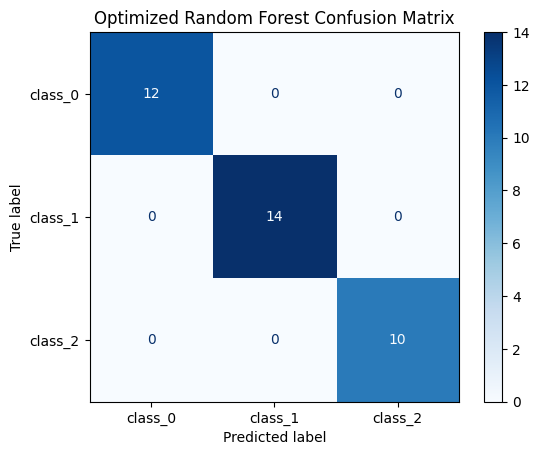

In [17]:
#Confusion matrix
best_predictions = best_rf_model.predict(X_test)

cm = confusion_matrix(
    y_test,
    best_predictions
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=wine.target_names
)

disp.plot(cmap="Blues")

plt.title("Optimized Random Forest Confusion Matrix")
plt.show()

In [19]:
#Feature importance
from IPython.display import display

feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": best_rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

display(feature_importance)

,Feature,Importance
9,color_intensity,0.187580
6,flavanoids,0.159561
12,proline,0.146799
0,alcohol,0.117913
10,hue,0.101538
11,od280/od315_of_diluted_wines,0.096301
5,total_phenols,0.041514
4,magnesium,0.040131
1,malic_acid,0.033894
3,alcalinity_of_ash,0.025471


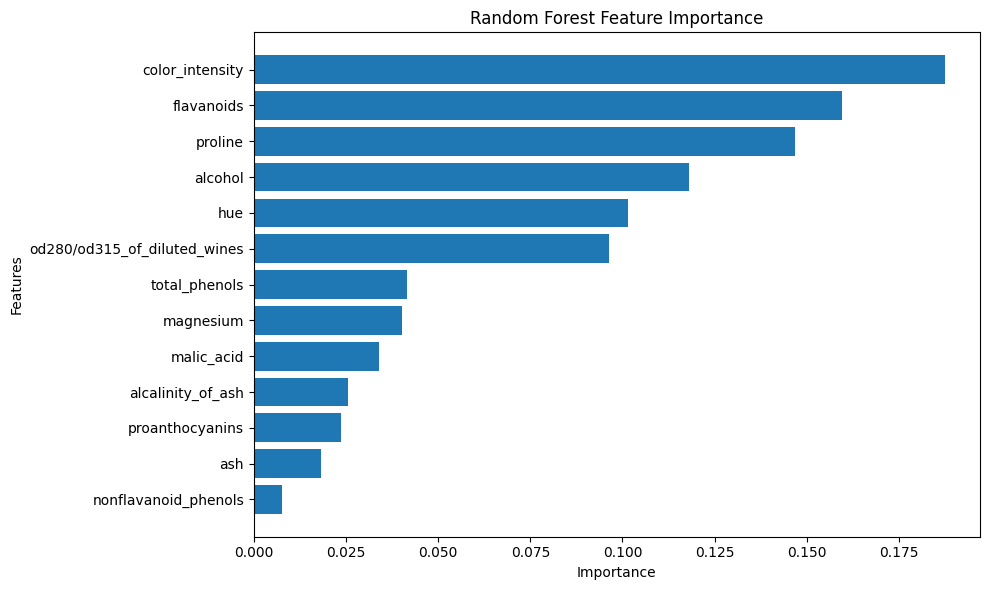

In [20]:
#Visualize feature importance
plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Features")
plt.title("Random Forest Feature Importance")

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [21]:
#Save the trained model
import joblib

joblib.dump(
    best_rf_model,
    "wine_ensemble_model.pkl"
)

print("Model saved successfully.")

#To load the model again
loaded_model = joblib.load("wine_ensemble_model.pkl")

sample_prediction = loaded_model.predict(X_test.iloc[[0]])

print("Predicted class:", wine.target_names[sample_prediction[0]])

Model saved successfully.
Predicted class: class_0


## Conclusion

In this project, multiple machine learning and ensemble
learning algorithms were implemented to classify wine categories.

The models were evaluated using cross-validation and
held-out test data.

Hyperparameter tuning was performed using GridSearchCV
to optimize Random Forest.

The final model was evaluated using accuracy, precision,
recall, F1-score and a confusion matrix.

The best-performing model was identified based on the
observed evaluation results.

## Model Evaluation and Observations

The Stacking Classifier achieved the highest mean
cross-validation accuracy of approximately 99.31%.

The Random Forest achieved 100% accuracy on the
held-out test dataset.

The results demonstrate that a model's performance
can differ between cross-validation and a single
test split.

Therefore, model selection should consider
cross-validation performance, score variability,
and final held-out test evaluation.


## Cross-Validation Fold Analysis

Random Forest achieved a mean cross-validation accuracy
of 98.62%, while Stacking achieved 99.31%.

Both models achieved 100% accuracy in four out of
five validation folds.

In the second fold, Random Forest achieved 93.10%
accuracy, whereas Stacking achieved 96.55%.

On the independent test dataset, Random Forest
achieved 100% accuracy and Stacking achieved 97.22%.

These results demonstrate that model performance
can vary across validation folds and held-out test data.

Both models are strong candidates for this dataset.
Further evaluation on additional unseen data would
be necessary before making claims about generalization.